# Olist: продажи, доставка и клиентский опыт

## Цель проекта

Оценить динамику заказов маркетплейса Olist, измерить качество выполнения
доставки и определить факторы, связанные с опозданиями и оценками покупателей.

Основной бизнес-вопрос: **почему доля опозданий в штате Rio de Janeiro (RJ)
заметно выше, чем в São Paulo (SP), и на каком этапе возникает разрыв?**

## Единицы анализа и определения

- Основная единица анализа — один заказ (`order_id`).
- GOV — стоимость товаров и доставки; это оборот заказов, а не бухгалтерская выручка или прибыль.
- Заказ считается опоздавшим, если календарная дата доставки позже обещанной даты.
- Анализ расстояния ограничен заказами с одним продавцом: для заказов с несколькими
  продавцами невозможно однозначно определить один маршрут.
- Прямолинейное расстояние рассчитано по медианным координатам ZIP-префиксов
  и не равно дорожному расстоянию.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.ticker import FuncFormatter

In [2]:
PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR / "data" / "raw").exists():
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data" / "raw"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

con = duckdb.connect()

## 1. Загрузка и проверка данных

In [3]:
TABLE_FILES = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "translation": "product_category_name_translation.csv",
}

for view_name, filename in TABLE_FILES.items():
    csv_path = (DATA_DIR / filename).as_posix().replace("'", "''")
    con.execute(
        f"""
        CREATE OR REPLACE VIEW {view_name} AS
        SELECT *
        FROM read_csv_auto('{csv_path}')
        """
    )

overview = pd.DataFrame(
    {
        "table": list(TABLE_FILES),
        "rows": [
            con.sql(f"SELECT COUNT(*) FROM {table_name}").fetchone()[0]
            for table_name in TABLE_FILES
        ],
    }
)
overview

,table,rows
0,customers,99441
1,orders,99441
2,order_items,112650
3,reviews,99224
4,products,32951
5,sellers,3095
6,geolocation,1000163
7,translation,71


In [4]:
order_key_check = con.sql("""
SELECT
    COUNT(*) AS rows_count,
    COUNT(DISTINCT order_id) AS unique_orders,
    COUNT(*) - COUNT(DISTINCT order_id) AS duplicate_order_ids
FROM orders
""").df()
order_key_check

,rows_count,unique_orders,duplicate_order_ids
0,99441,99441,0


Таблица `orders` имеет grain **одна строка = один заказ**:
`order_id` уникален. В `order_items` одному заказу может соответствовать
несколько товаров, поэтому стоимость сначала агрегируется до уровня заказа.

In [5]:
con.execute("""
CREATE OR REPLACE TEMP VIEW delivery_features AS
SELECT
    order_id,
    customer_id,
    order_purchase_timestamp,
    order_delivered_carrier_date,
    order_delivered_customer_date,
    order_estimated_delivery_date,
    EXTRACT(
        EPOCH FROM (order_delivered_customer_date - order_purchase_timestamp)
    ) / 86400.0 AS delivery_days,
    CAST(order_delivered_customer_date AS DATE)
        - CAST(order_estimated_delivery_date AS DATE) AS delay_days,
    delay_days > 0 AS is_late
FROM orders
WHERE order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL
  AND order_estimated_delivery_date IS NOT NULL
""")

## 2. Динамика заказов и GOV

In [6]:
monthly_metrics = con.sql("""
WITH delivered_orders AS (
    SELECT
        o.order_id,
        o.order_purchase_timestamp,
        SUM(oi.price) AS products_total,
        SUM(oi.freight_value) AS freight_total,
        SUM(oi.price + oi.freight_value) AS gross_order_value
    FROM orders AS o
    JOIN order_items AS oi USING (order_id)
    WHERE o.order_status = 'delivered'
    GROUP BY o.order_id, o.order_purchase_timestamp
),
monthly AS (
    SELECT
        DATE_TRUNC('month', order_purchase_timestamp) AS month,
        COUNT(*) AS delivered_orders,
        SUM(gross_order_value) AS gross_order_value,
        AVG(gross_order_value) AS average_order_value,
        SUM(products_total) AS products_total,
        SUM(freight_total) AS freight_total,
        100.0 * SUM(freight_total)
            / NULLIF(SUM(gross_order_value), 0) AS freight_share_pct
    FROM delivered_orders
    GROUP BY month
),
analysis_period AS (
    SELECT *
    FROM monthly
    WHERE month BETWEEN DATE '2017-01-01' AND DATE '2018-08-01'
),
with_previous AS (
    SELECT
        *,
        LAG(gross_order_value) OVER (ORDER BY month) AS previous_month_gov
    FROM analysis_period
)
SELECT
    month,
    delivered_orders,
    ROUND(gross_order_value, 2) AS gross_order_value,
    ROUND(average_order_value, 2) AS average_order_value,
    ROUND(products_total, 2) AS products_total,
    ROUND(freight_total, 2) AS freight_total,
    ROUND(freight_share_pct, 2) AS freight_share_pct,
    ROUND(
        100.0 * (gross_order_value - previous_month_gov)
        / NULLIF(previous_month_gov, 0),
        2
    ) AS mom_gov_pct
FROM with_previous
ORDER BY month
""").df()

monthly_metrics

,month,delivered_orders,gross_order_value,average_order_value,products_total,freight_total,freight_share_pct,mom_gov_pct
0,2017-01-01,750,127482.37,169.98,111798.36,15684.01,12.30,NaN
1,2017-02-01,1653,271239.32,164.09,234223.40,37015.92,13.65,112.77
2,2017-03-01,2546,414330.95,162.74,359198.85,55132.10,13.31,52.75
3,2017-04-01,2303,390812.40,169.70,340669.68,50142.72,12.83,-5.68
4,2017-05-01,3546,566851.40,159.86,489338.25,77513.15,13.67,45.04
5,2017-06-01,3135,490050.37,156.32,421923.37,68127.00,13.90,-13.55
6,2017-07-01,3872,566299.08,146.25,481604.52,84694.56,14.96,15.56
7,2017-08-01,4193,645832.36,154.03,554699.70,91132.66,14.11,14.04
8,2017-09-01,4150,701077.49,168.93,607399.67,93677.82,13.36,8.55
9,2017-10-01,4478,751117.01,167.73,648247.65,102869.36,13.70,7.14


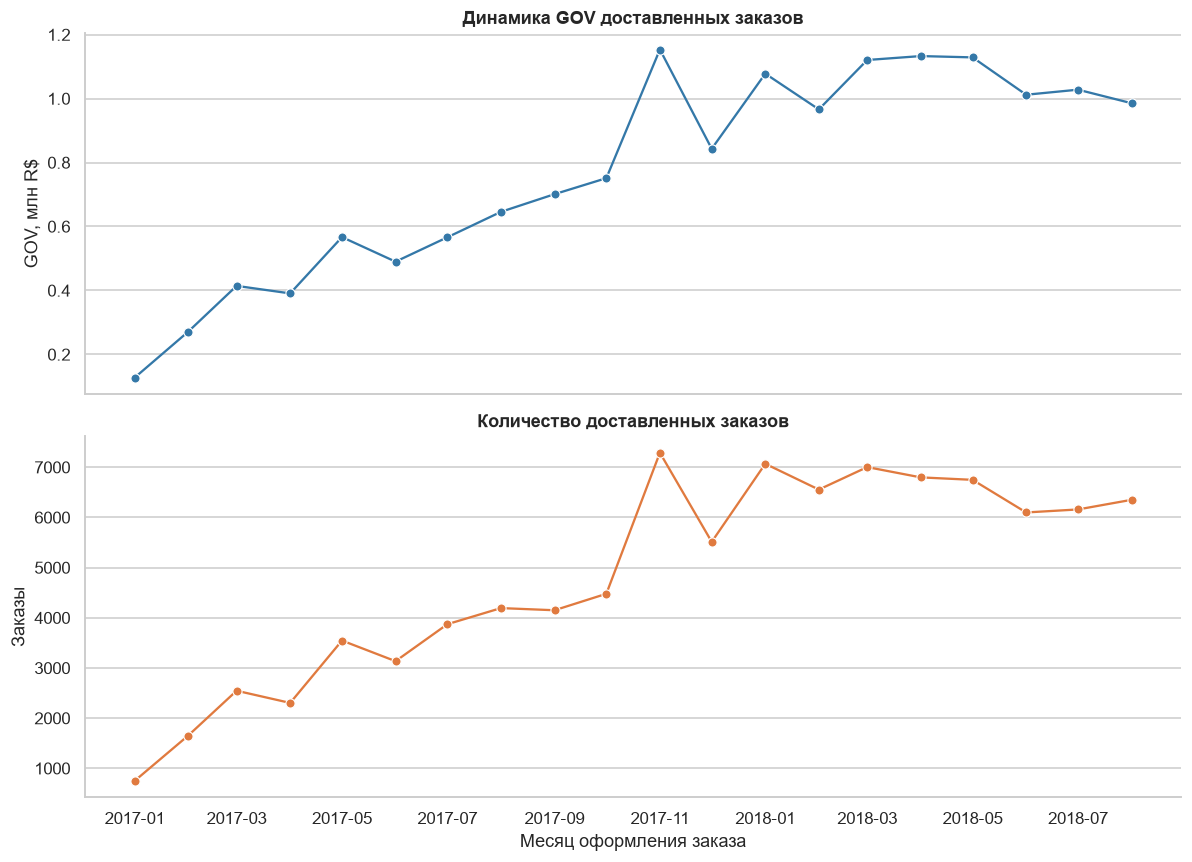

In [7]:
monthly_plot = monthly_metrics.copy()
monthly_plot["month"] = pd.to_datetime(monthly_plot["month"])

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

sns.lineplot(
    data=monthly_plot,
    x="month",
    y="gross_order_value",
    marker="o",
    color="#3478a8",
    ax=axes[0],
)
axes[0].set(
    title="Динамика GOV доставленных заказов",
    xlabel="",
    ylabel="GOV, млн R$",
)
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1_000_000:.1f}"))

sns.lineplot(
    data=monthly_plot,
    x="month",
    y="delivered_orders",
    marker="o",
    color="#e07a3f",
    ax=axes[1],
)
axes[1].set(
    title="Количество доставленных заказов",
    xlabel="Месяц оформления заказа",
    ylabel="Заказы",
)

for ax in axes:
    ax.grid(axis="x", visible=False)
    sns.despine(ax=ax)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "monthly-dynamics.png", bbox_inches="tight")
plt.show()

Период с января 2017 года показывает неравномерный рост объёма заказов и GOV:
месяцы роста чередуются со снижениями. Сентябрь–декабрь 2016 года исключены
из основного сравнения из-за фрагментарности. Август 2018 года оставлен,
но интерпретируется осторожно: последние оформленные и впоследствии доставленные
заказы относятся к 29 августа.

## 3. Выполнение заказов и опоздания

In [8]:
status_distribution = con.sql("""
SELECT
    order_status,
    COUNT(*) AS orders_count,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS share_pct
FROM orders
GROUP BY order_status
ORDER BY orders_count DESC
""").df()
status_distribution

,order_status,orders_count,share_pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


In [9]:
late_summary = con.sql("""
SELECT
    CASE WHEN is_late THEN 'Late' ELSE 'On time' END AS delivery_status,
    COUNT(*) AS orders_count,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS share_pct
FROM delivery_features
GROUP BY is_late
ORDER BY is_late
""").df()
late_summary

,delivery_status,orders_count,share_pct
0,On time,89936,93.23
1,Late,6534,6.77


Среди доставленных заказов с известными фактической и обещанной датами
**6,77% были доставлены позже обещанной календарной даты**.

## 4. Опоздания и отзывы

В таблице отзывов встречаются повторения и случаи, когда один `review_id`
связан с несколькими заказами. Сначала исключаются неоднозначные идентификаторы,
затем для каждого заказа сохраняется последний отзыв по времени ответа.
Это аналитическое допущение: последний отзыв считается наиболее актуальным.

In [10]:
con.execute("""
CREATE OR REPLACE TEMP VIEW clean_reviews AS
WITH valid_review_ids AS (
    SELECT review_id
    FROM reviews
    GROUP BY review_id
    HAVING COUNT(DISTINCT order_id) = 1
),
ranked_reviews AS (
    SELECT
        r.*,
        ROW_NUMBER() OVER (
            PARTITION BY r.order_id
            ORDER BY r.review_answer_timestamp DESC, r.review_id
        ) AS review_rank
    FROM reviews AS r
    JOIN valid_review_ids USING (review_id)
)
SELECT *
FROM ranked_reviews
WHERE review_rank = 1
""")

In [11]:
review_quality_check = con.sql("""
SELECT
    COUNT(*) AS rows_count,
    COUNT(DISTINCT order_id) AS unique_orders,
    COUNT(*) - COUNT(DISTINCT order_id) AS duplicate_orders
FROM clean_reviews
""").df()
review_quality_check

,rows_count,unique_orders,duplicate_orders
0,97530,97530,0


In [12]:
delay_review_metrics = con.sql("""
WITH bucketed AS (
    SELECT
        df.order_id,
        cr.review_score,
        df.delay_days,
        CASE
            WHEN df.delay_days <= 0 THEN 0
            WHEN df.delay_days = 1 THEN 1
            WHEN df.delay_days BETWEEN 2 AND 3 THEN 2
            WHEN df.delay_days BETWEEN 4 AND 7 THEN 3
            WHEN df.delay_days BETWEEN 8 AND 14 THEN 4
            WHEN df.delay_days BETWEEN 15 AND 30 THEN 5
            ELSE 6
        END AS delay_bucket_num,
        CASE
            WHEN df.delay_days <= 0 THEN 'On time'
            WHEN df.delay_days = 1 THEN '1 day'
            WHEN df.delay_days BETWEEN 2 AND 3 THEN '2–3 days'
            WHEN df.delay_days BETWEEN 4 AND 7 THEN '4–7 days'
            WHEN df.delay_days BETWEEN 8 AND 14 THEN '8–14 days'
            WHEN df.delay_days BETWEEN 15 AND 30 THEN '15–30 days'
            ELSE '31+ days'
        END AS delay_bucket
    FROM delivery_features AS df
    JOIN clean_reviews AS cr USING (order_id)
)
SELECT
    delay_bucket_num,
    delay_bucket,
    COUNT(*) AS orders_count,
    ROUND(AVG(review_score), 2) AS average_review_score
FROM bucketed
GROUP BY delay_bucket_num, delay_bucket
ORDER BY delay_bucket_num
""").df()

delay_review_metrics

,delay_bucket_num,delay_bucket,orders_count,average_review_score
0,0,On time,88467,4.29
1,1,1 day,813,3.74
2,2,2–3 days,1020,2.94
3,3,4–7 days,1731,2.11
4,4,8–14 days,1431,1.67
5,5,15–30 days,990,1.61
6,6,31+ days,322,2.05


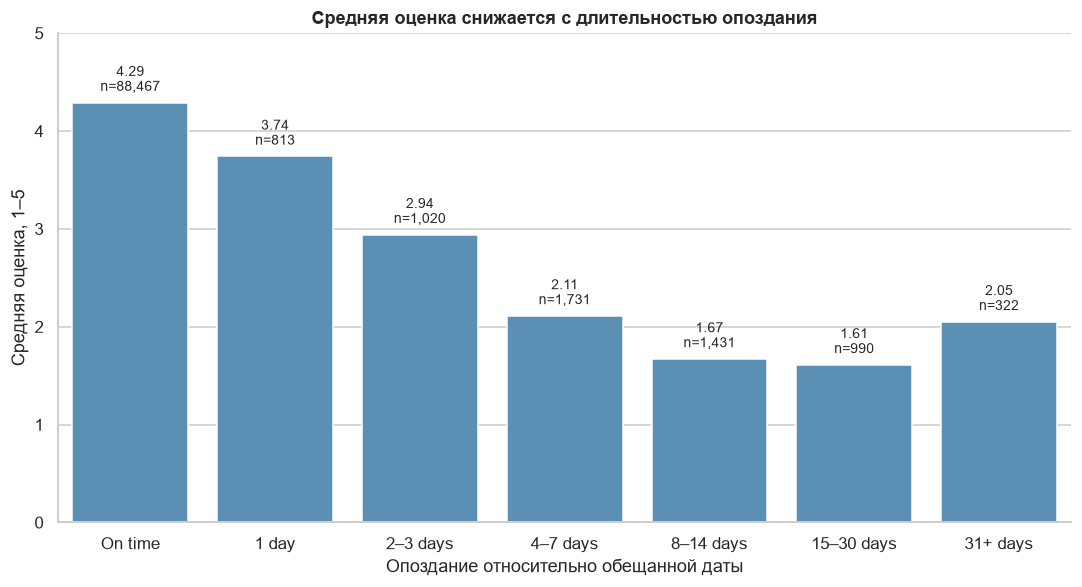

In [13]:
fig, ax = plt.subplots(figsize=(10, 5.5))

bars = sns.barplot(
    data=delay_review_metrics,
    x="delay_bucket",
    y="average_review_score",
    color="#4c92c3",
    ax=ax,
)

for bar, row in zip(bars.patches, delay_review_metrics.itertuples(), strict=True):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.08,
        f"{row.average_review_score:.2f}\nn={row.orders_count:,}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax.set(
    title="Средняя оценка снижается с длительностью опоздания",
    xlabel="Опоздание относительно обещанной даты",
    ylabel="Средняя оценка, 1–5",
    ylim=(0, 5),
)
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "delay-and-review-score.png", bbox_inches="tight")
plt.show()

Средняя оценка составляет 4,29 для своевременно доставленных заказов,
3,74 при задержке на один день и 1,61 при задержке на 15–30 дней.
Наиболее резкое снижение наблюдается уже в первую неделю. Связь не доказывает
причинность: на оценку также влияют качество товара, продавец и коммуникация.

## 5. География и категории

In [14]:
state_metrics = con.sql("""
SELECT
    c.customer_state,
    COUNT(*) AS delivered_orders,
    COUNT(*) FILTER (WHERE df.is_late) AS late_orders,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE df.is_late) / COUNT(*),
        2
    ) AS late_share_pct,
    ROUND(AVG(df.delivery_days), 2) AS average_delivery_days
FROM delivery_features AS df
JOIN customers AS c
    ON df.customer_id = c.customer_id
GROUP BY c.customer_state
ORDER BY delivered_orders DESC
""").df()
state_metrics

,customer_state,delivered_orders,late_orders,late_share_pct,average_delivery_days
0,SP,40494,1820,4.49,8.76
1,RJ,12350,1495,12.11,15.31
2,MG,11354,519,4.57,12.01
3,RS,5344,325,6.08,15.30
4,PR,4923,199,4.04,11.99
5,SC,3546,291,8.21,14.95
6,BA,3256,396,12.16,19.34
7,DF,2080,118,5.67,12.97
8,ES,1995,214,10.73,15.79
9,GO,1957,128,6.54,15.61


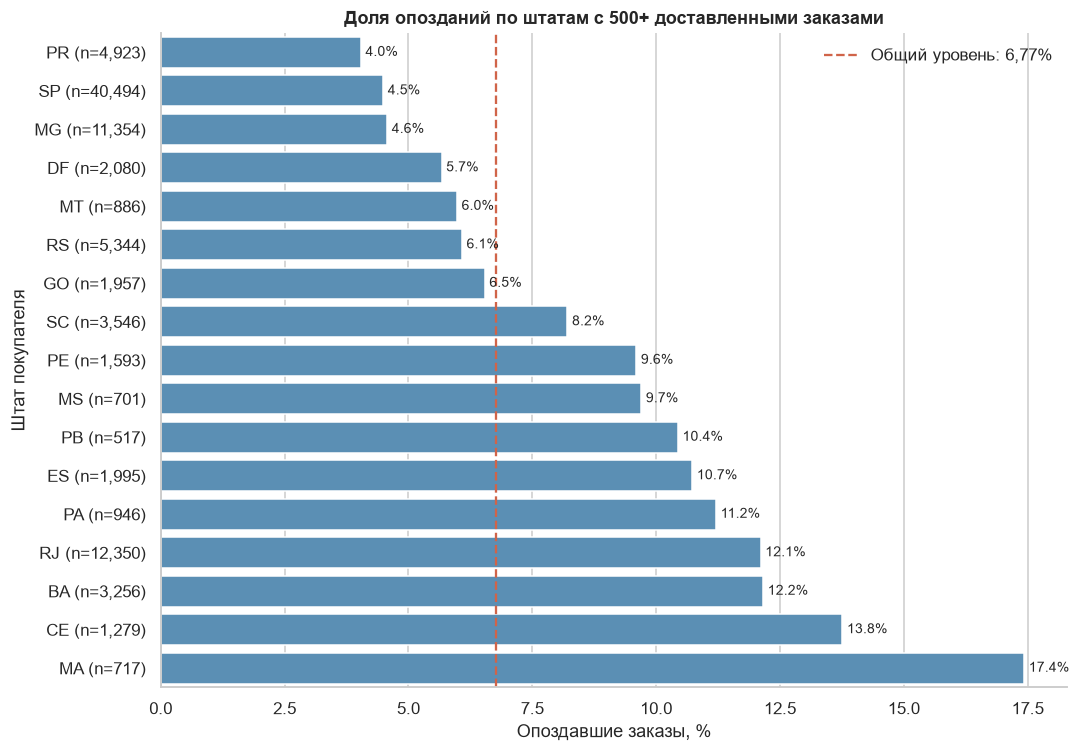

In [15]:
state_plot = (
    state_metrics.query("delivered_orders >= 500")
    .sort_values("late_share_pct")
    .copy()
)
state_plot["state_label"] = (
    state_plot["customer_state"]
    + " (n="
    + state_plot["delivered_orders"].map("{:,}".format)
    + ")"
)

fig, ax = plt.subplots(figsize=(10, 7))
bars = sns.barplot(
    data=state_plot,
    x="late_share_pct",
    y="state_label",
    color="#4c92c3",
    ax=ax,
)
ax.bar_label(bars.containers[0], fmt="%.1f%%", padding=3, fontsize=9)
ax.axvline(6.77, color="#d06449", linestyle="--", linewidth=1.5, label="Общий уровень: 6,77%")
ax.set(
    title="Доля опозданий по штатам с 500+ доставленными заказами",
    xlabel="Опоздавшие заказы, %",
    ylabel="Штат покупателя",
)
ax.legend(frameon=False)
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "late-share-by-state.png", bbox_inches="tight")
plt.show()

SP сочетает наибольший объём доставленных заказов и сравнительно низкую долю
опозданий — около 4,5%. В RJ доля составляет около 12,1%, поэтому этот штат
выбран для дальнейшего исследования.

In [16]:
category_metrics = con.sql("""
WITH order_categories AS (
    SELECT DISTINCT
        oi.order_id,
        COALESCE(
            t.product_category_name_english,
            p.product_category_name
        ) AS category
    FROM order_items AS oi
    JOIN products AS p USING (product_id)
    LEFT JOIN translation AS t
        ON p.product_category_name = t.product_category_name
)
SELECT
    oc.category,
    COUNT(*) AS delivered_orders,
    COUNT(*) FILTER (WHERE df.is_late) AS late_orders,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE df.is_late) / COUNT(*),
        2
    ) AS late_share_pct,
    ROUND(AVG(df.delivery_days), 2) AS average_delivery_days
FROM order_categories AS oc
JOIN delivery_features AS df USING (order_id)
WHERE oc.category IS NOT NULL
GROUP BY oc.category
HAVING COUNT(*) > 500
ORDER BY late_share_pct DESC, delivered_orders DESC
""").df()
category_metrics

,category,delivered_orders,late_orders,late_share_pct,average_delivery_days
0,baby,2809,226,8.05,12.68
1,office_furniture,1254,101,8.05,20.64
2,electronics,2517,192,7.63,12.92
3,musical_instruments,611,46,7.53,13.07
4,health_beauty,8647,649,7.51,12.08
5,bed_bath_table,9272,689,7.43,12.99
6,watches_gifts,5493,406,7.39,12.81
7,construction_tools_construction,736,54,7.34,10.86
8,auto,3809,278,7.30,12.33
9,furniture_decor,6307,449,7.12,13.07


Среди массовых категорий нет одного экстремального лидера по доле опозданий.
`office_furniture` выделяется длительным средним сроком доставки — около
20,6 дня. Категорию нельзя считать непосредственной причиной: различия могут
быть связаны с габаритами, географией продавцов и составом заказов.

Заказы с несколькими категориями входят в каждую соответствующую категорию,
поэтому строки этой таблицы не являются взаимоисключающими группами.

## 6. Почему RJ опаздывает чаще?

### 6.1 Подготовка приблизительных расстояний

В таблице геолокации один ZIP-префикс может иметь несколько координат.
Для каждой комбинации ZIP + штат используется медианная широта и долгота.

In [17]:
con.execute("""
CREATE OR REPLACE TEMP VIEW zip_coordinates AS
SELECT
    geolocation_zip_code_prefix AS zip_prefix,
    geolocation_state AS state,
    MEDIAN(geolocation_lat) AS latitude,
    MEDIAN(geolocation_lng) AS longitude,
    MAX(geolocation_lat) - MIN(geolocation_lat) AS lat_diff,
    MAX(geolocation_lng) - MIN(geolocation_lng) AS lng_diff,
    COUNT(*) AS coordinate_rows
FROM geolocation
GROUP BY geolocation_zip_code_prefix, geolocation_state
""")

In [18]:
con.execute("""
CREATE OR REPLACE TEMP VIEW route_distances AS
WITH order_sellers AS (
    SELECT DISTINCT order_id, seller_id
    FROM order_items
),
single_seller_orders AS (
    SELECT order_id, MIN(seller_id) AS seller_id
    FROM order_sellers
    GROUP BY order_id
    HAVING COUNT(*) = 1
),
route_coordinates AS (
    SELECT
        sso.order_id,
        sso.seller_id,
        s.seller_state,
        c.customer_state,
        s.seller_zip_code_prefix,
        c.customer_zip_code_prefix,
        sg.latitude AS seller_latitude,
        sg.longitude AS seller_longitude,
        cg.latitude AS customer_latitude,
        cg.longitude AS customer_longitude
    FROM single_seller_orders AS sso
    JOIN orders AS o USING (order_id)
    JOIN sellers AS s USING (seller_id)
    JOIN customers AS c USING (customer_id)
    JOIN zip_coordinates AS sg
        ON s.seller_zip_code_prefix = sg.zip_prefix
       AND s.seller_state = sg.state
    JOIN zip_coordinates AS cg
        ON c.customer_zip_code_prefix = cg.zip_prefix
       AND c.customer_state = cg.state
),
haversine AS (
    SELECT
        *,
        POW(
            SIN((RADIANS(customer_latitude) - RADIANS(seller_latitude)) / 2),
            2
        )
        + COS(RADIANS(seller_latitude))
        * COS(RADIANS(customer_latitude))
        * POW(
            SIN((RADIANS(customer_longitude) - RADIANS(seller_longitude)) / 2),
            2
        ) AS a
    FROM route_coordinates
)
SELECT
    order_id,
    seller_id,
    seller_state,
    customer_state,
    seller_zip_code_prefix,
    customer_zip_code_prefix,
    seller_latitude,
    seller_longitude,
    customer_latitude,
    customer_longitude,
    6371 * 2 * ASIN(SQRT(a)) AS straight_line_distance_km
FROM haversine
""")

In [19]:
route_grain_check = con.sql("""
SELECT
    COUNT(*) AS rows_count,
    COUNT(DISTINCT order_id) AS unique_orders,
    COUNT(*) - COUNT(DISTINCT order_id) AS duplicate_orders
FROM route_distances
""").df()
route_grain_check

,rows_count,unique_orders,duplicate_orders
0,96333,96333,0


In [20]:
geolocation_quality = con.sql("""
WITH thresholds AS (
    SELECT
        QUANTILE_CONT(lat_diff, 0.999) AS lat_diff_p999,
        QUANTILE_CONT(lng_diff, 0.999) AS lng_diff_p999
    FROM zip_coordinates
),
zip_quality AS (
    SELECT
        z.zip_prefix,
        z.state,
        z.lat_diff > t.lat_diff_p999
            OR z.lng_diff > t.lng_diff_p999 AS suspicious_zip
    FROM zip_coordinates AS z
    CROSS JOIN thresholds AS t
),
route_quality AS (
    SELECT
        rd.order_id,
        sq.suspicious_zip OR cq.suspicious_zip AS suspicious_route
    FROM route_distances AS rd
    JOIN zip_quality AS sq
        ON rd.seller_zip_code_prefix = sq.zip_prefix
       AND rd.seller_state = sq.state
    JOIN zip_quality AS cq
        ON rd.customer_zip_code_prefix = cq.zip_prefix
       AND rd.customer_state = cq.state
)
SELECT
    COUNT(*) AS routes_count,
    COUNT(*) FILTER (WHERE suspicious_route) AS suspicious_routes,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE suspicious_route) / COUNT(*),
        3
    ) AS suspicious_share_pct
FROM route_quality
""").df()
geolocation_quality

,routes_count,suspicious_routes,suspicious_share_pct
0,96333,63,0.065


Только 63 маршрута (около 0,07%) используют ZIP-префиксы с экстремальным
внутренним разбросом координат. Их исключение почти не меняет основные
характеристики распределения расстояний. При этом отдельные согласованно
ошибочные координаты могут не выявляться таким правилом, поэтому максимальные
расстояния не интерпретируются буквально.

### 6.2 Расстояние и доля опозданий

In [21]:
distance_late_metrics = con.sql("""
WITH bucketed AS (
    SELECT
        df.order_id,
        df.is_late,
        rd.straight_line_distance_km,
        CASE
            WHEN rd.customer_state = 'SP' THEN 'SP'
            WHEN rd.customer_state = 'RJ' THEN 'RJ'
            ELSE 'Other states'
        END AS state_group,
        CASE
            WHEN rd.straight_line_distance_km < 100 THEN 1
            WHEN rd.straight_line_distance_km < 300 THEN 2
            WHEN rd.straight_line_distance_km < 500 THEN 3
            WHEN rd.straight_line_distance_km < 850 THEN 4
            WHEN rd.straight_line_distance_km < 1400 THEN 5
            WHEN rd.straight_line_distance_km < 2000 THEN 6
            ELSE 7
        END AS distance_group_num,
        CASE
            WHEN rd.straight_line_distance_km < 100 THEN '0–100'
            WHEN rd.straight_line_distance_km < 300 THEN '100–300'
            WHEN rd.straight_line_distance_km < 500 THEN '300–500'
            WHEN rd.straight_line_distance_km < 850 THEN '500–850'
            WHEN rd.straight_line_distance_km < 1400 THEN '850–1400'
            WHEN rd.straight_line_distance_km < 2000 THEN '1400–2000'
            ELSE '2000+'
        END AS distance_group
    FROM delivery_features AS df
    JOIN route_distances AS rd USING (order_id)
)
SELECT
    state_group,
    distance_group_num,
    distance_group,
    COUNT(*) AS orders_count,
    COUNT(*) FILTER (WHERE is_late) AS late_orders,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE is_late) / COUNT(*),
        2
    ) AS late_share_pct
FROM bucketed
GROUP BY state_group, distance_group_num, distance_group
ORDER BY distance_group_num, state_group
""").df()
distance_late_metrics

,state_group,distance_group_num,distance_group,orders_count,late_orders,late_share_pct
0,Other states,1,0–100,1098,33,3.01
1,RJ,1,0–100,788,42,5.33
2,SP,1,0–100,15763,720,4.57
3,Other states,2,100–300,2508,125,4.98
4,RJ,2,100–300,896,88,9.82
5,SP,2,100–300,9675,473,4.89
6,Other states,3,300–500,8192,416,5.08
7,RJ,3,300–500,5701,713,12.51
8,SP,3,300–500,9242,431,4.66
9,Other states,4,500–850,12358,807,6.53


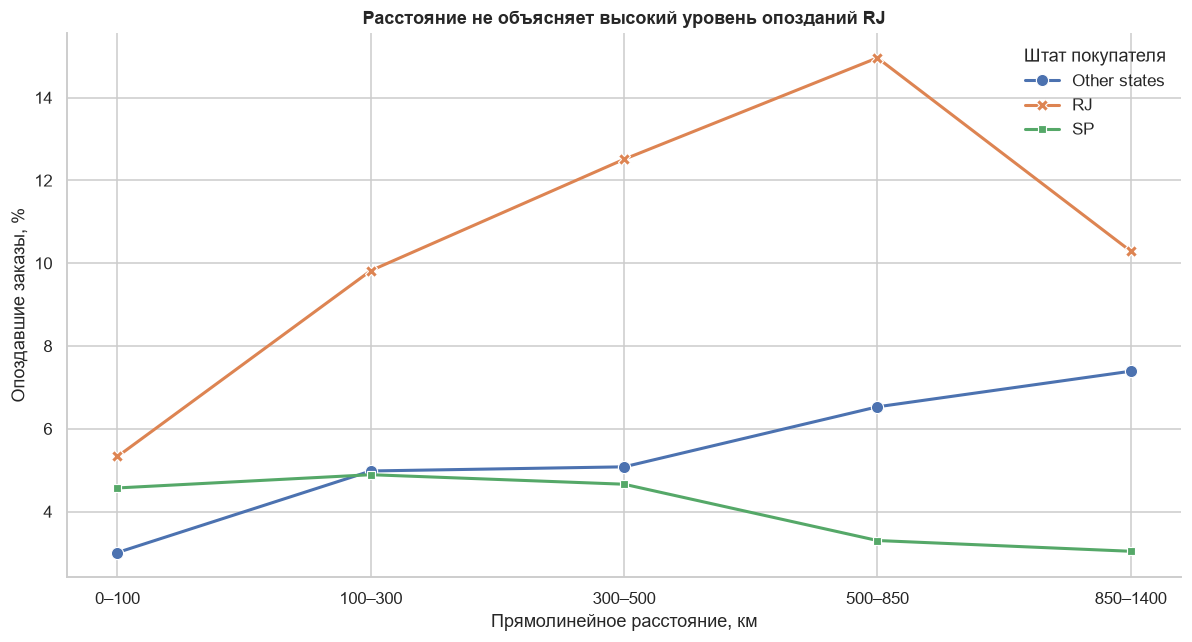

In [22]:
distance_plot = distance_late_metrics.query("distance_group_num <= 5").copy()

fig, ax = plt.subplots(figsize=(11, 6))

sns.lineplot(
    data=distance_plot,
    x="distance_group_num",
    y="late_share_pct",
    hue="state_group",
    style="state_group",
    markers=True,
    dashes=False,
    linewidth=2,
    markersize=8,
    ax=ax,
)

group_labels = (
    distance_plot[["distance_group_num", "distance_group"]]
    .drop_duplicates()
    .sort_values("distance_group_num")
)
ax.set_xticks(group_labels["distance_group_num"])
ax.set_xticklabels(group_labels["distance_group"])
ax.set(
    title="Расстояние не объясняет высокий уровень опозданий RJ",
    xlabel="Прямолинейное расстояние, км",
    ylabel="Опоздавшие заказы, %",
)
ax.legend(title="Штат покупателя", frameon=False)
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "distance-and-late-share.png", bbox_inches="tight")
plt.show()

Для остальных штатов доля опозданий в целом растёт с расстоянием. Однако RJ
остаётся заметно хуже SP внутри основных диапазонов, поэтому высокий уровень
опозданий RJ нельзя объяснить только длиной маршрута.

На графике показаны интервалы до 1400 км. В более дальних интервалах для RJ
и SP остаётся слишком мало заказов для устойчивого визуального сравнения.

### 6.3 Сопоставимые маршруты из SP

Сравниваются две крупные группы с близким средним расстоянием 300–500 км:
**SP → SP** и **SP → RJ**. Перед сравнением исключаются строки с нарушенной
хронологией `purchase ≤ carrier ≤ customer`.

In [23]:
route_date_quality = con.sql("""
WITH comparable_routes AS (
    SELECT
        df.order_id,
        rd.seller_state,
        rd.customer_state,
        df.order_purchase_timestamp,
        df.order_delivered_carrier_date,
        df.order_delivered_customer_date
    FROM delivery_features AS df
    JOIN route_distances AS rd USING (order_id)
    WHERE rd.seller_state = 'SP'
      AND rd.customer_state IN ('SP', 'RJ')
      AND rd.straight_line_distance_km >= 300
      AND rd.straight_line_distance_km < 500
)
SELECT
    seller_state,
    customer_state,
    COUNT(*) AS orders_count,
    COUNT(*) FILTER (
        WHERE order_delivered_carrier_date IS NULL
    ) AS missing_carrier_date,
    COUNT(*) FILTER (
        WHERE order_delivered_carrier_date < order_purchase_timestamp
    ) AS carrier_before_purchase,
    COUNT(*) FILTER (
        WHERE order_delivered_customer_date < order_delivered_carrier_date
    ) AS customer_before_carrier
FROM comparable_routes
GROUP BY seller_state, customer_state
ORDER BY customer_state
""").df()
route_date_quality

,seller_state,customer_state,orders_count,missing_carrier_date,carrier_before_purchase,customer_before_carrier
0,SP,RJ,4952,0,9,0
1,SP,SP,4841,0,9,2


In [24]:
route_stage_metrics = con.sql("""
WITH comparable_routes AS (
    SELECT
        df.order_id,
        rd.seller_state,
        rd.customer_state,
        rd.straight_line_distance_km,
        df.is_late,
        df.delay_days,
        EXTRACT(
            EPOCH FROM (
                df.order_delivered_carrier_date - df.order_purchase_timestamp
            )
        ) / 86400.0 AS purchase_to_carrier_days,
        EXTRACT(
            EPOCH FROM (
                df.order_delivered_customer_date - df.order_delivered_carrier_date
            )
        ) / 86400.0 AS carrier_to_customer_days,
        EXTRACT(
            EPOCH FROM (
                df.order_delivered_customer_date - df.order_purchase_timestamp
            )
        ) / 86400.0 AS actual_delivery_days,
        EXTRACT(
            EPOCH FROM (
                df.order_estimated_delivery_date - df.order_purchase_timestamp
            )
        ) / 86400.0 AS promised_delivery_days
    FROM delivery_features AS df
    JOIN route_distances AS rd USING (order_id)
    WHERE rd.seller_state = 'SP'
      AND rd.customer_state IN ('SP', 'RJ')
      AND rd.straight_line_distance_km >= 300
      AND rd.straight_line_distance_km < 500
      AND df.order_delivered_carrier_date >= df.order_purchase_timestamp
      AND df.order_delivered_customer_date >= df.order_delivered_carrier_date
)
SELECT
    seller_state || ' → ' || customer_state AS route,
    COUNT(*) AS orders_count,
    ROUND(AVG(straight_line_distance_km), 1) AS average_distance_km,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE is_late) / COUNT(*),
        2
    ) AS late_share_pct,
    ROUND(AVG(purchase_to_carrier_days), 2) AS purchase_to_carrier_days,
    ROUND(AVG(carrier_to_customer_days), 2) AS carrier_to_customer_days,
    ROUND(AVG(actual_delivery_days), 2) AS actual_delivery_days,
    ROUND(AVG(promised_delivery_days), 2) AS promised_delivery_days,
    QUANTILE_CONT(delay_days, 0.75) AS delay_p75,
    QUANTILE_CONT(delay_days, 0.90) AS delay_p90,
    QUANTILE_CONT(delay_days, 0.95) AS delay_p95
FROM comparable_routes
GROUP BY seller_state, customer_state
ORDER BY customer_state
""").df()
route_stage_metrics

,route,orders_count,average_distance_km,late_share_pct,purchase_to_carrier_days,carrier_to_customer_days,actual_delivery_days,promised_delivery_days,delay_p75,delay_p90,delay_p95
0,SP → RJ,4943,373.1,13.13,3.47,12.29,15.76,26.50,-7.0,4.0,13.0
1,SP → SP,4830,365.9,4.74,3.11,7.26,10.37,20.85,-8.0,-3.0,0.0


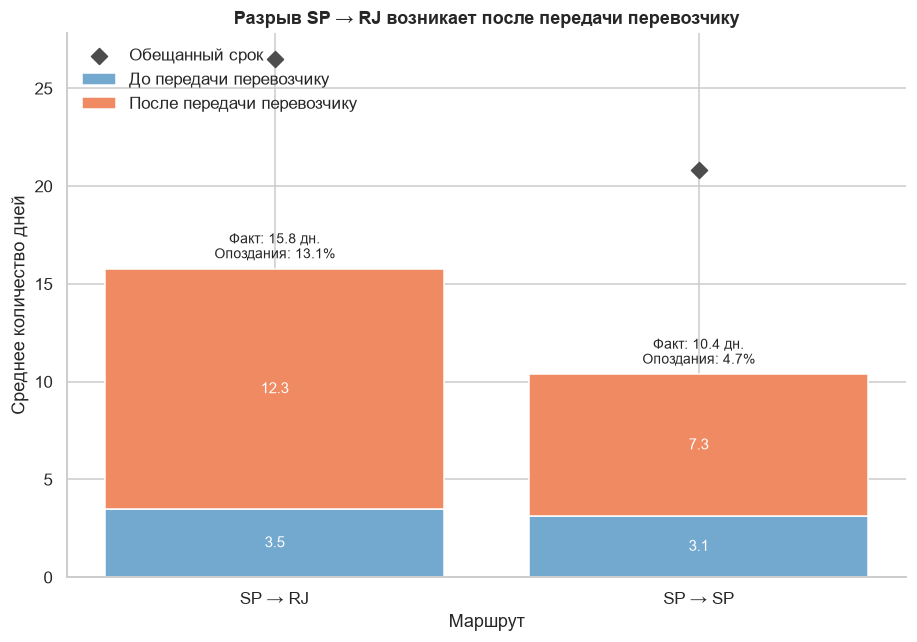

In [25]:
fig, ax = plt.subplots(figsize=(8.5, 6))
x = range(len(route_stage_metrics))

pre_carrier = route_stage_metrics["purchase_to_carrier_days"]
in_transit = route_stage_metrics["carrier_to_customer_days"]

bars_pre = ax.bar(
    x,
    pre_carrier,
    label="До передачи перевозчику",
    color="#74a9cf",
)
bars_transit = ax.bar(
    x,
    in_transit,
    bottom=pre_carrier,
    label="После передачи перевозчику",
    color="#ef8a62",
)
ax.scatter(
    x,
    route_stage_metrics["promised_delivery_days"],
    marker="D",
    s=55,
    color="#4d4d4d",
    label="Обещанный срок",
    zorder=3,
)

ax.bar_label(bars_pre, fmt="%.1f", label_type="center", color="white", fontsize=10)
ax.bar_label(bars_transit, fmt="%.1f", label_type="center", color="white", fontsize=10)

for index, row in route_stage_metrics.iterrows():
    ax.text(
        index,
        row["actual_delivery_days"] + 0.35,
        f"Факт: {row['actual_delivery_days']:.1f} дн.\nОпоздания: {row['late_share_pct']:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax.set_xticks(list(x))
ax.set_xticklabels(route_stage_metrics["route"])
ax.set(
    title="Разрыв SP → RJ возникает после передачи перевозчику",
    xlabel="Маршрут",
    ylabel="Среднее количество дней",
)
ax.legend(frameon=False, loc="upper left")
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "sp-rj-delivery-stages.png", bbox_inches="tight")
plt.show()

В сопоставимом диапазоне расстояний маршруты SP → RJ опаздывают примерно
в 13% случаев против менее 5% для SP → SP. Фактическая доставка в RJ занимает
примерно на 5,4 дня больше. Разница до передачи перевозчику составляет менее
половины дня, а около пяти дополнительных дней возникает после передачи
перевозчику.

Для RJ заранее устанавливается более длинный обещанный срок, но верхний хвост
остаётся проблемным: p90 задержки уже положителен, тогда как для SP он остаётся
отрицательным. Следовательно, средний обещанный срок не полностью отражает
риск затяжных доставок.

## 7. Выводы и рекомендации

### Основные наблюдения

1. Среди доставленных заказов с известными датами 6,77% доставлены позже
   обещанной календарной даты.
2. Опоздания связаны с ухудшением оценок: средний балл снижается с 4,29
   для своевременной доставки до 2,11 при задержке на 4–7 дней.
3. RJ сочетает большой объём заказов и высокую долю опозданий — около 12,1%
   против 4,5% в SP.
4. Расстояние связано с опозданиями, но не объясняет разрыв RJ. Для маршрутов
   одного продавца из SP на расстоянии 300–500 км доля опозданий SP → RJ
   примерно втрое выше SP → SP.
5. Почти весь разрыв среднего фактического срока возникает после передачи
   заказа перевозчику.

### Возможное объяснение

Результаты указывают на различия в работе транспортного этапа направления
SP → RJ: маршрутизации, сортировочных узлах, региональной инфраструктуре
или составе перевозчиков. Это гипотезы, а не установленные причины.

### Практические рекомендации

- В первую очередь исследовать транспортный этап SP → RJ на данных
  перевозчиков и сортировочных узлов.
- Контролировать не только средний срок, но также p90/p95: именно верхний хвост
  приводит к нарушению обещанной даты.
- Отдельно отслеживать задержки свыше четырёх дней, поскольку они связаны
  с резким снижением оценки покупателя.

### Ограничения

- В данных нет идентификатора перевозчика и событий между передачей заказа
  перевозчику и вручением покупателю.
- Расстояние прямолинейное и рассчитано по приблизительным координатам ZIP.
- Анализ расстояний исключает заказы с несколькими продавцами.
- Наблюдаемые связи не доказывают причинность.
- GOV не является показателем прибыли или чистой выручки Olist.